In [1]:
!pip install optuna


[notice] A new release of pip is available: 24.3.1 -> 25.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import sklearn 
import lightgbm
import scipy 
import statsmodels 
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import KFold, GroupKFold, StratifiedKFold, TimeSeriesSplit
from collections import Counter
import random
import shap
import time
import optuna

c:\Users\Kirill\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 1.  Что такое leave-one-out? Укажите ограничения и сильные стороны.

**Leave-One-Out (LOO)** - это специальный случай кросс-валидации, где:
- Количество фолдов равно количеству наблюдений в датасете (k = n)
- На каждой итерации одно наблюдение используется как тестовое, остальные (n-1) - как тренировочные
- Процесс повторяется n раз, каждый раз с новым тестовым наблюдением

**Преимущества:**
- Максимально использует данные для обучения (n-1 наблюдений)
- Не зависит от случайного разбиения - детерминированный результат
- Малая смещенность оценки, особенно для небольших датасетов
- Не требует настройки параметра k

**Ограничения:**
- Высокая вычислительная стоимость (n моделей нужно обучить)
- Высокая дисперсия оценки, особенно при коррелированных данных
- Может быть неустойчивым при наличии выбросов
- Не подходит для больших датасетов (слишком долгий расчет)

### 2.  Как работают Grid Search, Randomized Grid Search и Bayesian optimization?

**Grid Search (Полный перебор)**
- Систематически проверяет все комбинации гиперпараметров из заданной сетки

- Работает по принципу "brute force"

- Гарантирует нахождение лучшей комбинации в пределах сетки

***Преимущества/Ограничения***
- Плюсы: Полнота поиска
- Минусы: Высокая вычислительная стоимость

***Randomized Grid Search (Случайный поиск)***
- Случайно выбирает n_iter комбинаций из пространства параметров

- Часто находит хорошие решения быстрее чем Grid Search

- Особенно эффективен когда некоторые параметры не важны

***Преимущества/Ограничения***
- Плюсы: Быстрее, хорошо для высокоразмерных пространств
- Минусы: Может пропустить оптимальные комбинации

### 3.  Объясните классификацию методов отбора признаков. Объясните, как работают Пирсон и Хи-квадрат. Объясните, как работает Лассо. Объясните, что такое важность перестановок (permutation importance). Ознакомьтесь с SHAP.

***Pearson Correlation***
- Измеряет линейную зависимость между признаком и целевой переменной

- Диапазон значений: [-1, 1]

- Быстрый расчет: ρ = cov(X,Y) / (σ_X * σ_Y)

- Ограничения: Только линейные зависимости, чувствителен к выбросам

***Chi-square Test***
- Проверяет независимость категориальных переменных

- Основан на сравнении наблюдаемых и ожидаемых частот

χ² = Σ((O-E)² / E)

- Применение: Отбор категориальных признаков для классификации

***Lasso (L1 Regularization)***
- Добавляет штраф за абсолютные значения весов к функции потерь

Loss = MSE + α * Σ|w_i|

- Обнуляет веса нерелевантных признаков

- Преимущества: Автоматический отбор признаков, интерпретируемость

***Permutation Importance***
- Измеряет падение качества при случайном перемешивании признака

- Если признак важен - перемешивание сильно ухудшит качество

- Преимущества: Модельно-агностичный, надежный

- Недостатки: Вычислительно дорогой

***SHAP (SHapley Additive exPlanations)***
- Основан на теории игр Шепли для распределения "вклада" признаков

- Вычисляет средний маржинальный вклад признака во все возможные коалиции

- Преимущества: Теоретически обоснованный, глобальная и локальная интерпретируемость

- Недостатки: Вычислительно сложный для больших датасетов

In [3]:
df = pd.read_json('data/two-sigma-connect-rental-listing-inquiries/train.json')

In [4]:
df.head()

,bathrooms,bedrooms,building_id,created,description,display_address,features,latitude,listing_id,longitude,manager_id,photos,price,street_address,interest_level
4,1.0,1,8579a0b0d54db803821a35a4a615e97a,2016-06-16 05:55:27,Spacious 1 Bedroom 1 Bathroom in Williamsburg!...,145 Borinquen Place,"[Dining Room, Pre-War, Laundry in Building, Di...",40.7108,7170325,-73.9539,a10db4590843d78c784171a107bdacb4,[https://photos.renthop.com/2/7170325_3bb5ac84...,2400,145 Borinquen Place,medium
6,1.0,2,b8e75fc949a6cd8225b455648a951712,2016-06-01 05:44:33,BRAND NEW GUT RENOVATED TRUE 2 BEDROOMFind you...,East 44th,"[Doorman, Elevator, Laundry in Building, Dishw...",40.7513,7092344,-73.9722,955db33477af4f40004820b4aed804a0,[https://photos.renthop.com/2/7092344_7663c19a...,3800,230 East 44th,low
9,1.0,2,cd759a988b8f23924b5a2058d5ab2b49,2016-06-14 15:19:59,**FLEX 2 BEDROOM WITH FULL PRESSURIZED WALL**L...,East 56th Street,"[Doorman, Elevator, Laundry in Building, Laund...",40.7575,7158677,-73.9625,c8b10a317b766204f08e613cef4ce7a0,[https://photos.renthop.com/2/7158677_c897a134...,3495,405 East 56th Street,medium
10,1.5,3,53a5b119ba8f7b61d4e010512e0dfc85,2016-06-24 07:54:24,A Brand New 3 Bedroom 1.5 bath ApartmentEnjoy ...,Metropolitan Avenue,[],40.7145,7211212,-73.9425,5ba989232d0489da1b5f2c45f6688adc,[https://photos.renthop.com/2/7211212_1ed4542e...,3000,792 Metropolitan Avenue,medium
15,1.0,0,bfb9405149bfff42a92980b594c28234,2016-06-28 03:50:23,Over-sized Studio w abundant closets. Availabl...,East 34th Street,"[Doorman, Elevator, Fitness Center, Laundry in...",40.7439,7225292,-73.9743,2c3b41f588fbb5234d8a1e885a436cfa,[https://photos.renthop.com/2/7225292_901f1984...,2795,340 East 34th Street,low


In [5]:
df['created_timestamp'] = pd.to_datetime(df['created'])

In [6]:
def int_encode(df):
    df['interest_level'] = df['interest_level'].replace({'low': 0, 'medium': 1, 'high': 2}).astype('int8')
    df.reset_index()
    df = df.reset_index(drop=True)
    return df

In [7]:
int_encode(df)

C:\Users\Kirill\AppData\Local\Temp\ipykernel_19124\2503377057.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['interest_level'] = df['interest_level'].replace({'low': 0, 'medium': 1, 'high': 2}).astype('int8')


,bathrooms,bedrooms,building_id,created,description,display_address,features,latitude,listing_id,longitude,manager_id,photos,price,street_address,interest_level,created_timestamp
0,1.0,1,8579a0b0d54db803821a35a4a615e97a,2016-06-16 05:55:27,Spacious 1 Bedroom 1 Bathroom in Williamsburg!...,145 Borinquen Place,"[Dining Room, Pre-War, Laundry in Building, Di...",40.7108,7170325,-73.9539,a10db4590843d78c784171a107bdacb4,[https://photos.renthop.com/2/7170325_3bb5ac84...,2400,145 Borinquen Place,1,2016-06-16 05:55:27
1,1.0,2,b8e75fc949a6cd8225b455648a951712,2016-06-01 05:44:33,BRAND NEW GUT RENOVATED TRUE 2 BEDROOMFind you...,East 44th,"[Doorman, Elevator, Laundry in Building, Dishw...",40.7513,7092344,-73.9722,955db33477af4f40004820b4aed804a0,[https://photos.renthop.com/2/7092344_7663c19a...,3800,230 East 44th,0,2016-06-01 05:44:33
2,1.0,2,cd759a988b8f23924b5a2058d5ab2b49,2016-06-14 15:19:59,**FLEX 2 BEDROOM WITH FULL PRESSURIZED WALL**L...,East 56th Street,"[Doorman, Elevator, Laundry in Building, Laund...",40.7575,7158677,-73.9625,c8b10a317b766204f08e613cef4ce7a0,[https://photos.renthop.com/2/7158677_c897a134...,3495,405 East 56th Street,1,2016-06-14 15:19:59
3,1.5,3,53a5b119ba8f7b61d4e010512e0dfc85,2016-06-24 07:54:24,A Brand New 3 Bedroom 1.5 bath ApartmentEnjoy ...,Metropolitan Avenue,[],40.7145,7211212,-73.9425,5ba989232d0489da1b5f2c45f6688adc,[https://photos.renthop.com/2/7211212_1ed4542e...,3000,792 Metropolitan Avenue,1,2016-06-24 07:54:24
4,1.0,0,bfb9405149bfff42a92980b594c28234,2016-06-28 03:50:23,Over-sized Studio w abundant closets. Availabl...,East 34th Street,"[Doorman, Elevator, Fitness Center, Laundry in...",40.7439,7225292,-73.9743,2c3b41f588fbb5234d8a1e885a436cfa,[https://photos.renthop.com/2/7225292_901f1984...,2795,340 East 34th Street,0,2016-06-28 03:50:23
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49347,1.0,3,92bbbf38baadfde0576fc496bd41749c,2016-04-05 03:58:33,There is 700 square feet of recently renovated...,W 171 Street,"[Elevator, Dishwasher, Hardwood Floors]",40.8433,6824800,-73.9396,a61e21da3ba18c7a3d54cfdcc247e1f8,[https://photos.renthop.com/2/6824800_0682be16...,2800,620 W 171 Street,0,2016-04-05 03:58:33
49348,1.0,2,5565db9b7cba3603834c4aa6f2950960,2016-04-02 02:25:31,"2 bedroom apartment with updated kitchen, rece...",Broadway,"[Common Outdoor Space, Cats Allowed, Dogs Allo...",40.8198,6813268,-73.9578,8f90e5e10e8a2d7cf997f016d89230eb,[https://photos.renthop.com/2/6813268_1e6fcc32...,2395,3333 Broadway,1,2016-04-02 02:25:31
49349,1.0,1,67997a128056ee1ed7d046bbb856e3c7,2016-04-26 05:42:03,No Brokers Fee * Never Lived 1 Bedroom 1 Bathr...,210 Brighton 15th St,"[Dining Room, Elevator, Pre-War, Laundry in Bu...",40.5765,6927093,-73.9554,a10db4590843d78c784171a107bdacb4,[https://photos.renthop.com/2/6927093_93a52104...,1850,210 Brighton 15th St,1,2016-04-26 05:42:03
49350,1.0,2,3c0574a740154806c18bdf1fddd3d966,2016-04-19 02:47:33,Wonderful Bright Chelsea 2 Bedroom apartment o...,West 21st Street,"[Pre-War, Laundry in Unit, Dishwasher, No Fee,...",40.7448,6892816,-74.0017,c3cd45f4381ac371507090e9ffabea80,[https://photos.renthop.com/2/6892816_1a8d087a...,4195,350 West 21st Street,1,2016-04-19 02:47:33


In [8]:
def clear_features(df):
    for idx, row in df.iterrows():
        if isinstance(row['features'], list):
            cleaned_features = []
            for feature in row['features']:
                cleaned_feature = (feature.replace(' ', '')
                                          .replace('"', '')
                                          .replace("'", '')
                                          .replace('[', '')
                                          .replace(']', '')
                                          .strip())
                cleaned_features.append(cleaned_feature)
            df.at[idx, 'features'] = cleaned_features
    return df

In [9]:
df = clear_features(df)

In [10]:
features_list = ['Elevator', 'HardwoodFloors', 'CatsAllowed', 'DogsAllowed', 'Doorman', 'Dishwasher', 'NoFee', 'LaundryinBuilding', 'FitnessCenter', 'Pre-War', 'LaundryinUnit', 'RoofDeck', 'OutdoorSpace', 'DiningRoom', 'HighSpeedInternet', 'Balcony', 'SwimmingPool', 'LaundryInBuilding', 'NewConstruction', 'Terrace']

In [11]:
for f in features_list:
    df[f] = 0
df.head()

,bathrooms,bedrooms,building_id,created,description,display_address,features,latitude,listing_id,longitude,...,LaundryinUnit,RoofDeck,OutdoorSpace,DiningRoom,HighSpeedInternet,Balcony,SwimmingPool,LaundryInBuilding,NewConstruction,Terrace
4,1.0,1,8579a0b0d54db803821a35a4a615e97a,2016-06-16 05:55:27,Spacious 1 Bedroom 1 Bathroom in Williamsburg!...,145 Borinquen Place,"[DiningRoom, Pre-War, LaundryinBuilding, Dishw...",40.7108,7170325,-73.9539,...,0,0,0,0,0,0,0,0,0,0
6,1.0,2,b8e75fc949a6cd8225b455648a951712,2016-06-01 05:44:33,BRAND NEW GUT RENOVATED TRUE 2 BEDROOMFind you...,East 44th,"[Doorman, Elevator, LaundryinBuilding, Dishwas...",40.7513,7092344,-73.9722,...,0,0,0,0,0,0,0,0,0,0
9,1.0,2,cd759a988b8f23924b5a2058d5ab2b49,2016-06-14 15:19:59,**FLEX 2 BEDROOM WITH FULL PRESSURIZED WALL**L...,East 56th Street,"[Doorman, Elevator, LaundryinBuilding, Laundry...",40.7575,7158677,-73.9625,...,0,0,0,0,0,0,0,0,0,0
10,1.5,3,53a5b119ba8f7b61d4e010512e0dfc85,2016-06-24 07:54:24,A Brand New 3 Bedroom 1.5 bath ApartmentEnjoy ...,Metropolitan Avenue,[],40.7145,7211212,-73.9425,...,0,0,0,0,0,0,0,0,0,0
15,1.0,0,bfb9405149bfff42a92980b594c28234,2016-06-28 03:50:23,Over-sized Studio w abundant closets. Availabl...,East 34th Street,"[Doorman, Elevator, FitnessCenter, LaundryinBu...",40.7439,7225292,-73.9743,...,0,0,0,0,0,0,0,0,0,0


In [12]:
for feature in features_list:
    mask_train = df['features'].apply(lambda x: feature in x if isinstance(x, list) else False)
    df.loc[mask_train, feature] = 1
df.head()

,bathrooms,bedrooms,building_id,created,description,display_address,features,latitude,listing_id,longitude,...,LaundryinUnit,RoofDeck,OutdoorSpace,DiningRoom,HighSpeedInternet,Balcony,SwimmingPool,LaundryInBuilding,NewConstruction,Terrace
4,1.0,1,8579a0b0d54db803821a35a4a615e97a,2016-06-16 05:55:27,Spacious 1 Bedroom 1 Bathroom in Williamsburg!...,145 Borinquen Place,"[DiningRoom, Pre-War, LaundryinBuilding, Dishw...",40.7108,7170325,-73.9539,...,0,0,0,1,0,0,0,0,0,0
6,1.0,2,b8e75fc949a6cd8225b455648a951712,2016-06-01 05:44:33,BRAND NEW GUT RENOVATED TRUE 2 BEDROOMFind you...,East 44th,"[Doorman, Elevator, LaundryinBuilding, Dishwas...",40.7513,7092344,-73.9722,...,0,0,0,0,0,0,0,0,0,0
9,1.0,2,cd759a988b8f23924b5a2058d5ab2b49,2016-06-14 15:19:59,**FLEX 2 BEDROOM WITH FULL PRESSURIZED WALL**L...,East 56th Street,"[Doorman, Elevator, LaundryinBuilding, Laundry...",40.7575,7158677,-73.9625,...,1,0,0,0,0,0,0,0,0,0
10,1.5,3,53a5b119ba8f7b61d4e010512e0dfc85,2016-06-24 07:54:24,A Brand New 3 Bedroom 1.5 bath ApartmentEnjoy ...,Metropolitan Avenue,[],40.7145,7211212,-73.9425,...,0,0,0,0,0,0,0,0,0,0
15,1.0,0,bfb9405149bfff42a92980b594c28234,2016-06-28 03:50:23,Over-sized Studio w abundant closets. Availabl...,East 34th Street,"[Doorman, Elevator, FitnessCenter, LaundryinBu...",40.7439,7225292,-73.9743,...,0,0,0,0,0,0,0,0,0,0


### 3.Методы разделения данных

In [13]:
def Xy_split(df, test_size=0.2, random_state=21):
    if not 0 <= test_size <= 1:
        raise ValueError("test_size должен быть между 0 и 1")
    
    random.seed(random_state)

    size = len(df)
    n_test = int(test_size * size)    
    n_train = size - n_test

    index_list = list(range(size))
    random.shuffle(index_list)

    index_train = index_list[:n_train]
    index_test = index_list[n_train:n_train + n_test]

    train = df.iloc[index_train].copy()
    test = df.iloc[index_test].copy()
    
    return train, test

In [14]:
def Xy_split_val(df, test_size=0.2, validation_size=0.2, random_state=21):
    if not 0 <= test_size <= 1 or not 0 <= validation_size <= 1:
        raise ValueError("test_size и validation_size должны быть между 0 и 1")
    if test_size + validation_size >= 1:
        raise ValueError("Сумма test_size и validation_size должна быть меньше 1")
    
    train_val, test = Xy_split(df, test_size=test_size, random_state=random_state)
    
    validation_size_adj = validation_size / (1 - test_size)
    train, val = Xy_split(train_val, test_size=validation_size_adj, random_state=random_state)
    
    return train, val, test

In [15]:
def Xy_split_by_date(df, split_date, date_column, random_state=21):
    if date_column not in df.columns:
        raise ValueError(f"Колонка '{date_column}' не найдена в датафрейме")
    
    train = df[df[date_column] > split_date]
    test = df[df[date_column] <= split_date]
    
    return train, test

In [16]:
def Xy_split_by_date_val(df, validation_date, test_date, date_column, random_state=21):
    if date_column not in df.columns:
        raise ValueError(f"Колонка '{date_column}' не найдена в датафрейме")
    
    if test_date >= validation_date:
        raise ValueError("test_date должна быть раньше validation_date")
    
    # Разделение данных
    test = df[df[date_column] <= test_date].copy()
    validation = df[(df[date_column] > test_date) & 
                   (df[date_column] <= validation_date)].copy()
    train = df[df[date_column] > validation_date].copy()
    
    return train, validation, test

- Детерминирована - значит предопределена (просто делаем seed константным для np.random)

### 4.Методы кросс-валидации

In [17]:
def k_fold(k, X, y, shuffle=True, random_state=42):
    if len(X) != len(y):
        raise ValueError("features and target must have same size!")
    if k <= 1 or k > len(X):
        raise ValueError(f"k must be between 2 and {len(X)}")
    
    indices = np.arange(len(X))
    
    if shuffle:
        np.random.seed(random_state)
        np.random.shuffle(indices)
    
    fold_sizes = np.full(k, len(X) // k, dtype=int)
    fold_sizes[:len(X) % k] += 1
    
    folds = []
    current = 0
    
    for i in range(k):
        start, stop = current, current + fold_sizes[i]
        test_indices = indices[start:stop]
        
        train_indices = np.concatenate([indices[:start], indices[stop:]])
        
        folds.append((train_indices, test_indices))
        current = stop
    
    return folds

In [18]:
def k_fold_grouped(k, df, group_field, shuffle=True, random_state=42):
    if group_field not in df.columns:
        raise ValueError(f"Поле '{group_field}' не найдено в DataFrame")
        
    unique_groups = df[group_field].unique()
    
    if k <= 1 or k > len(unique_groups):
        raise ValueError(f"k должно быть между 2 и {len(unique_groups)} (количество групп)")
    
    group_folds = k_fold(k, unique_groups, unique_groups, shuffle, random_state)
    
    sample_folds = []

    for group_train_idx, group_test_idx in group_folds:
        train_groups = unique_groups[group_train_idx]
        test_groups = unique_groups[group_test_idx]
        
        train_mask = df[group_field].isin(train_groups)
        test_mask = df[group_field].isin(test_groups)
        
        train_indices = df[train_mask].index.values
        test_indices = df[test_mask].index.values 
        
        sample_folds.append((train_indices, test_indices))
    
    return sample_folds
        

In [19]:
def k_fold_stratified(k, df, stratify_field, shuffle=True, random_state=42):
    if stratify_field not in df.columns:
        raise ValueError(f"Поле '{stratify_field}' не найдено в DataFrame")
    
    df_working = df.copy()
    
    df_working['_fold'] = -1

    unique_classes = df_working[stratify_field].unique()
    
    for class_val in unique_classes:
        class_mask = df_working[stratify_field] == class_val
        class_indices = df_working[class_mask].index

        n_class_samples = len(class_indices)
        fold_indices = np.arange(k).repeat(n_class_samples // k)

        remainder = n_class_samples % k
        if remainder > 0:
            fold_indices = np.concatenate([fold_indices, np.arange(remainder)])
        
        if shuffle:
            np.random.seed(random_state)
            np.random.shuffle(fold_indices)
        
        df_working.loc[class_indices, '_fold'] = fold_indices

    result_folds = []
    for fold in range(k):
        test_mask = df_working['_fold'] == fold
        test_indices = df_working[test_mask].index.values
        train_indices = df_working[~test_mask].index.values
        result_folds.append((train_indices, test_indices))
    
    return result_folds

In [20]:
def k_fold_timeseries(k, df, date_field, str="EW", shuffle=True, random_state=42, test_size=None, train_size=None):
    
    if date_field not in df.columns:
        raise ValueError(f"Поле '{date_field}' не найдено в DataFrame")
    
    df_working = df.copy()
    df_working = df_working.sort_values(date_field).reset_index(drop=True)
    n_samples = len(df_working)
    
    result_folds = []
    
    if str == "EW":
        if test_size is None:
            test_size = max(1, n_samples // (k + 1))
        
        for i in range(k):
            train_end = (i + 1) * test_size
            test_end = train_end + test_size
            
            if test_end <= n_samples:
                train_indices = np.arange(0, train_end)
                test_indices = np.arange(train_end, test_end)
                result_folds.append((train_indices, test_indices))
                
    elif str == "SW":
        if train_size is None or test_size is None:
            raise ValueError("Для SW стратегии необходимо указать train_size и test_size")
            
        for i in range(k):
            train_start = i * test_size
            train_end = train_start + train_size
            test_start = train_end
            test_end = test_start + test_size
            
            if test_end <= n_samples:
                train_indices = np.arange(train_start, train_end)
                test_indices = np.arange(test_start, test_end)
                result_folds.append((train_indices, test_indices))
                
    elif str == "FW":
        if train_size is None or test_size is None:
            raise ValueError("Для FW стратегии необходимо указать train_size и test_size")
            
        for i in range(k):
            start_idx = i * (train_size + test_size)
            train_end = start_idx + train_size
            test_end = train_end + test_size
            
            if test_end <= n_samples:
                train_indices = np.arange(start_idx, train_end)
                test_indices = np.arange(train_end, test_end)
                result_folds.append((train_indices, test_indices))
                
    else:
        raise ValueError("Стратегия должна быть 'EW', 'SW' или 'FW'")
    
    if len(result_folds) == 0:
        raise ValueError("Не удалось создать ни одного фолда. Проверьте параметры k, test_size и train_size")
    
    return result_folds

### 5. Сравнения

In [21]:
y = df.interest_level
X = df.drop('interest_level', axis = 1)

In [22]:
date_column = 'created_timestamp'

test_date = df[date_column].quantile(0.2)
validation_date = df[date_column].quantile(0.5)

#### Ручная реализация

In [23]:

handmade = dict()

train_1, test_1 = Xy_split(df, test_size=0.2)
train_2, val_2, test_2 = Xy_split_val(df, test_size=0.1, validation_size=0.3)
train_3, test_3 = Xy_split_by_date(df, split_date=test_date, date_column=date_column)
train_4, val_4, test_4 = Xy_split_by_date_val(
    df, 
    validation_date=validation_date, 
    test_date=test_date,
    date_column=date_column
)
handmade['rndm_split'] = [train_1, test_1]
handmade['rndm_split_val'] = [train_2, val_2, test_2]
handmade['date_split'] = [train_3, test_3]
handmade['date_split_val'] = [train_4, val_4, test_4]

#### sklearn

In [24]:
sklearn_splits = dict()

X_train_1, X_test_1, y_train_1, y_test_1 = train_test_split(
    X, y, test_size=0.2, random_state=21, stratify=y
)

train_1 = pd.concat([X_train_1, y_train_1], axis=1)
test_1 = pd.concat([X_test_1, y_test_1], axis=1)
sklearn_splits['rndm_split'] = [train_1, test_1]

X_temp, X_test_2, y_temp, y_test_2 = train_test_split(
    X, y, test_size=0.1, random_state=21, stratify=y 
)

val_ratio = 0.3 / (1 - 0.1)

X_train_2, X_val_2, y_train_2, y_val_2 = train_test_split(
    X_temp, y_temp, test_size=val_ratio, random_state=21, stratify=y_temp
)

train_2 = pd.concat([X_train_2, y_train_2], axis=1)
test_2 = pd.concat([X_test_2, y_test_2], axis=1)
val_2 = pd.concat([X_val_2, y_val_2], axis=1)
sklearn_splits['rndm_split_val'] = [train_2, val_2, test_2]

#### Сравнение

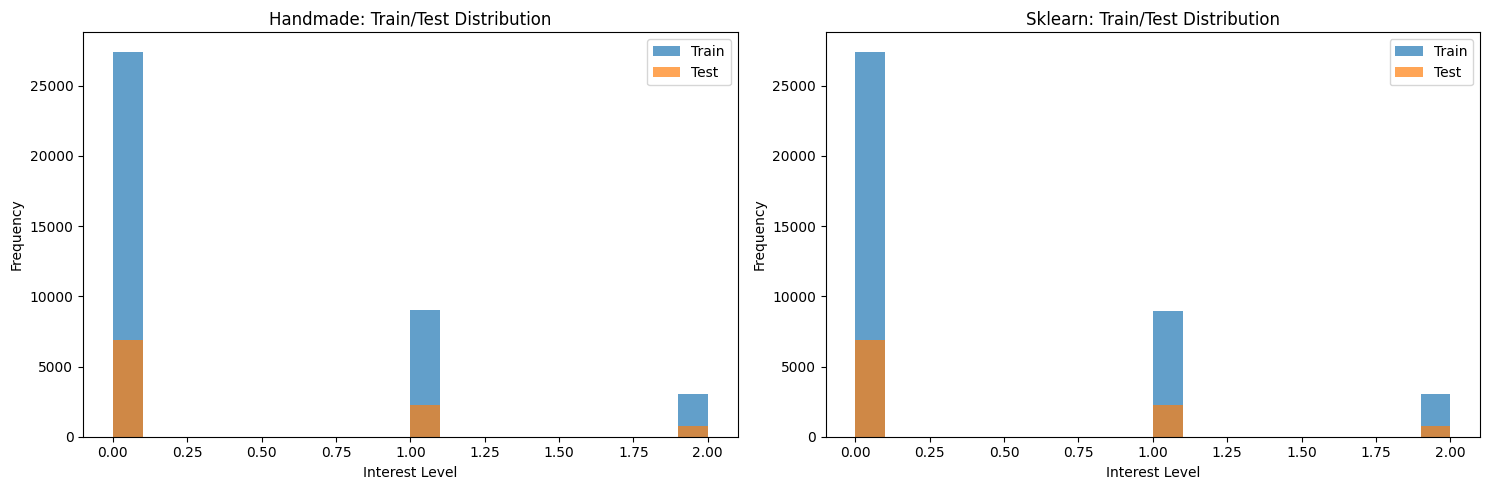

In [25]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Handmade
ax1.hist(handmade['rndm_split'][0]['interest_level'], alpha=0.7, label='Train', bins=20)
ax1.hist(handmade['rndm_split'][1]['interest_level'], alpha=0.7, label='Test', bins=20)
ax1.set_title('Handmade: Train/Test Distribution')
ax1.set_xlabel('Interest Level')
ax1.set_ylabel('Frequency')
ax1.legend()

# Sklearn
ax2.hist(sklearn_splits['rndm_split'][0]['interest_level'], alpha=0.7, label='Train', bins=20)
ax2.hist(sklearn_splits['rndm_split'][1]['interest_level'], alpha=0.7, label='Test', bins=20)
ax2.set_title('Sklearn: Train/Test Distribution')
ax2.set_xlabel('Interest Level')
ax2.set_ylabel('Frequency')
ax2.legend()

plt.tight_layout()
plt.show()

#### Видим, что распределения целевой переменной в sklearn и handmade реализациях похожи

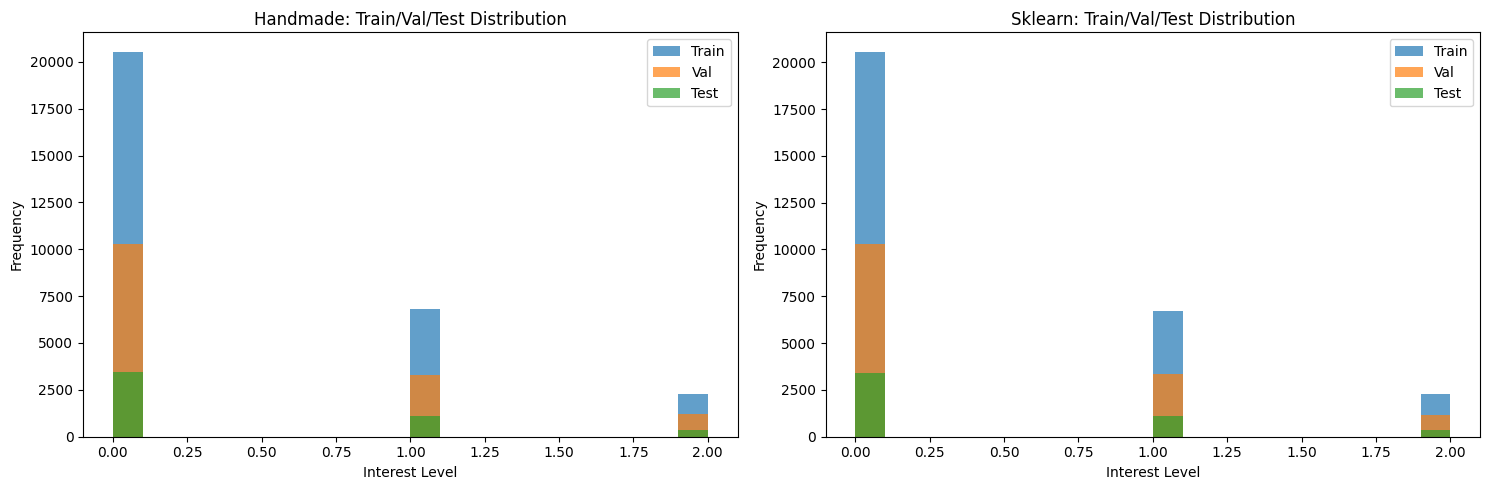

In [26]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Handmade
ax1.hist(handmade['rndm_split_val'][0]['interest_level'], alpha=0.7, label='Train', bins=20)
ax1.hist(handmade['rndm_split_val'][1]['interest_level'], alpha=0.7, label='Val', bins=20)
ax1.hist(handmade['rndm_split_val'][2]['interest_level'], alpha=0.7, label='Test', bins=20)
ax1.set_title('Handmade: Train/Val/Test Distribution')
ax1.set_xlabel('Interest Level')
ax1.set_ylabel('Frequency')
ax1.legend()

# Sklearn
ax2.hist(sklearn_splits['rndm_split_val'][0]['interest_level'], alpha=0.7, label='Train', bins=20)
ax2.hist(sklearn_splits['rndm_split_val'][1]['interest_level'], alpha=0.7, label='Val', bins=20)
ax2.hist(sklearn_splits['rndm_split_val'][2]['interest_level'], alpha=0.7, label='Test', bins=20)
ax2.set_title('Sklearn: Train/Val/Test Distribution')
ax2.set_xlabel('Interest Level')
ax2.set_ylabel('Frequency')
ax2.legend()

plt.tight_layout()
plt.show()

### Сравнение кросс-валидаций

In [27]:
k = 10

In [28]:
df.columns

Index(['bathrooms', 'bedrooms', 'building_id', 'created', 'description',
       'display_address', 'features', 'latitude', 'listing_id', 'longitude',
       'manager_id', 'photos', 'price', 'street_address', 'interest_level',
       'created_timestamp', 'Elevator', 'HardwoodFloors', 'CatsAllowed',
       'DogsAllowed', 'Doorman', 'Dishwasher', 'NoFee', 'LaundryinBuilding',
       'FitnessCenter', 'Pre-War', 'LaundryinUnit', 'RoofDeck', 'OutdoorSpace',
       'DiningRoom', 'HighSpeedInternet', 'Balcony', 'SwimmingPool',
       'LaundryInBuilding', 'NewConstruction', 'Terrace'],
      dtype='object')

#### Ручная реализация

In [29]:
handmade = dict()

k_folds = k_fold(k, X, y)
handmade['k-fold'] = k_folds

k_folds_grouped = k_fold_grouped(k, df, 'manager_id')
handmade['k-fold-grouped'] = k_folds_grouped

k_folds_stratified = k_fold_stratified(k, df, 'interest_level')
handmade['k-fold-stratified'] = k_folds_stratified

k_folds_timeseries = k_fold_timeseries(k, df, date_column)
handmade['k-fold-timeseries'] = k_folds_timeseries

#### sklearn

In [30]:
sklearn_splits = dict()

kf = KFold(n_splits=k, shuffle=True, random_state=21)
sklearn_splits['k-fold'] = list(kf.split(X, y))

gkf = GroupKFold(n_splits=k)
sklearn_splits['k-fold-grouped'] = list(gkf.split(X, y, groups=df['manager_id']))

skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=21)
sklearn_splits['k-fold-stratified'] = list(skf.split(X, y))

tscv = TimeSeriesSplit(n_splits=k)

df_sorted = df.sort_values('created_timestamp').reset_index(drop=True)
X_sorted = df_sorted.drop('interest_level', axis=1)
y_sorted = df_sorted['interest_level']
sklearn_splits['k-fold-timeseries'] = list(tscv.split(X_sorted, y_sorted))

#### Сравнение

In [31]:
for method in handmade.keys():
    print(f"\n{method}:")
    print(f"  Handmade: {len(handmade[method])} фолдов, тип индексов: {type(handmade[method][0][0])}")
    print(f"  Sklearn:  {len(sklearn_splits[method])} фолдов, тип индексов: {type(sklearn_splits[method][0][0])}")


k-fold:
  Handmade: 10 фолдов, тип индексов: <class 'numpy.ndarray'>
  Sklearn:  10 фолдов, тип индексов: <class 'numpy.ndarray'>

k-fold-grouped:
  Handmade: 10 фолдов, тип индексов: <class 'numpy.ndarray'>
  Sklearn:  10 фолдов, тип индексов: <class 'numpy.ndarray'>

k-fold-stratified:
  Handmade: 10 фолдов, тип индексов: <class 'numpy.ndarray'>
  Sklearn:  10 фолдов, тип индексов: <class 'numpy.ndarray'>

k-fold-timeseries:
  Handmade: 10 фолдов, тип индексов: <class 'numpy.ndarray'>
  Sklearn:  10 фолдов, тип индексов: <class 'numpy.ndarray'>


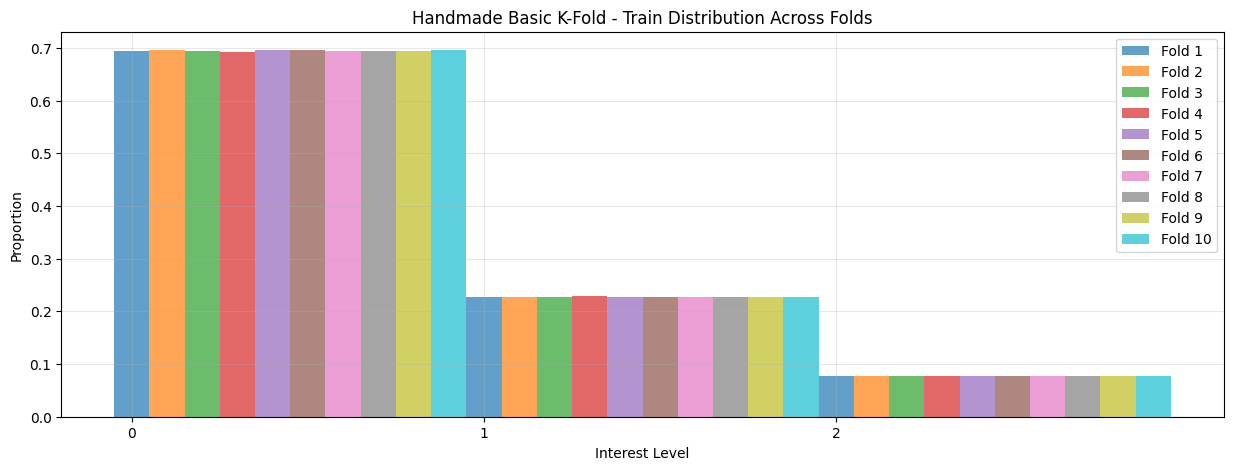

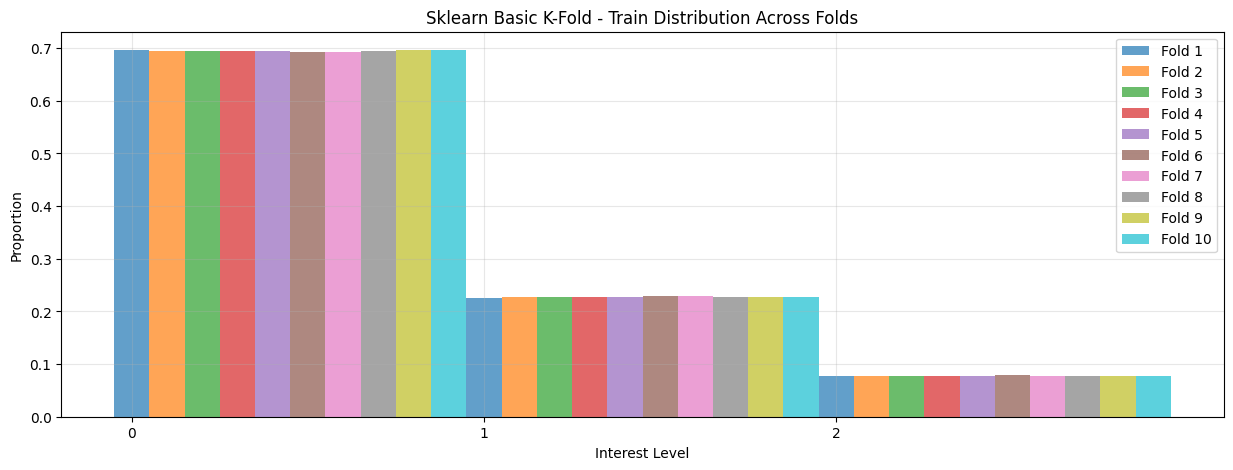

In [32]:
# Handmade Basic K-Fold
plt.figure(figsize=(15, 5))
for i, (train_idx, test_idx) in enumerate(handmade['k-fold']):
    train_dist = df.iloc[train_idx]['interest_level'].value_counts(normalize=True).sort_index()
    plt.bar(np.arange(len(train_dist)) + i*0.1, train_dist.values, width=0.1, alpha=0.7, label=f'Fold {i+1}')

plt.title('Handmade Basic K-Fold - Train Distribution Across Folds')
plt.xlabel('Interest Level')
plt.ylabel('Proportion')
plt.xticks(np.arange(len(train_dist)), train_dist.index)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Sklearn Basic K-Fold
plt.figure(figsize=(15, 5))
for i, (train_idx, test_idx) in enumerate(sklearn_splits['k-fold']):
    train_dist = df.iloc[train_idx]['interest_level'].value_counts(normalize=True).sort_index()
    plt.bar(np.arange(len(train_dist)) + i*0.1, train_dist.values, width=0.1, alpha=0.7, label=f'Fold {i+1}')

plt.title('Sklearn Basic K-Fold - Train Distribution Across Folds')
plt.xlabel('Interest Level')
plt.ylabel('Proportion')
plt.xticks(np.arange(len(train_dist)), train_dist.index)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

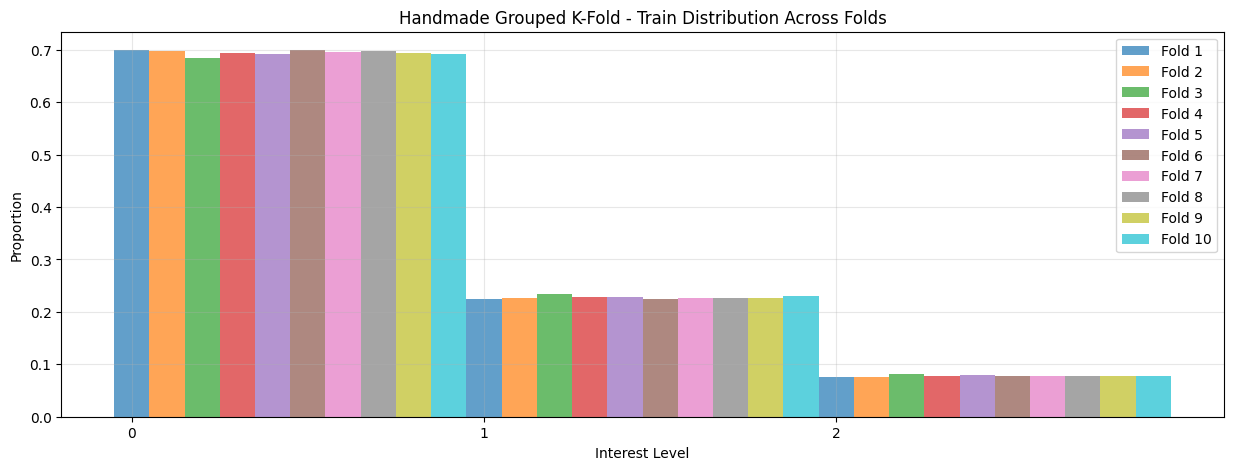

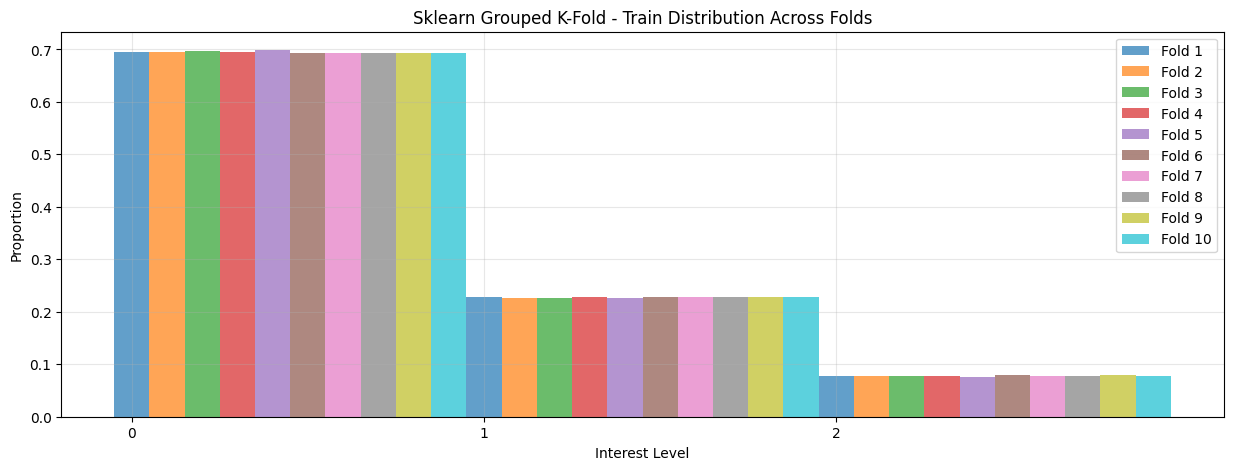

In [33]:
# Handmade Grouped K-Fold
plt.figure(figsize=(15, 5))
for i, (train_idx, test_idx) in enumerate(handmade['k-fold-grouped']):
    train_dist = df.loc[train_idx]['interest_level'].value_counts(normalize=True).sort_index()
    plt.bar(np.arange(len(train_dist)) + i*0.1, train_dist.values, width=0.1, alpha=0.7, label=f'Fold {i+1}')

plt.title('Handmade Grouped K-Fold - Train Distribution Across Folds')
plt.xlabel('Interest Level')
plt.ylabel('Proportion')
plt.xticks(np.arange(len(train_dist)), train_dist.index)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Sklearn Grouped K-Fold
plt.figure(figsize=(15, 5))
for i, (train_idx, test_idx) in enumerate(sklearn_splits['k-fold-grouped']):
    train_dist = df.iloc[train_idx]['interest_level'].value_counts(normalize=True).sort_index()
    plt.bar(np.arange(len(train_dist)) + i*0.1, train_dist.values, width=0.1, alpha=0.7, label=f'Fold {i+1}')

plt.title('Sklearn Grouped K-Fold - Train Distribution Across Folds')
plt.xlabel('Interest Level')
plt.ylabel('Proportion')
plt.xticks(np.arange(len(train_dist)), train_dist.index)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

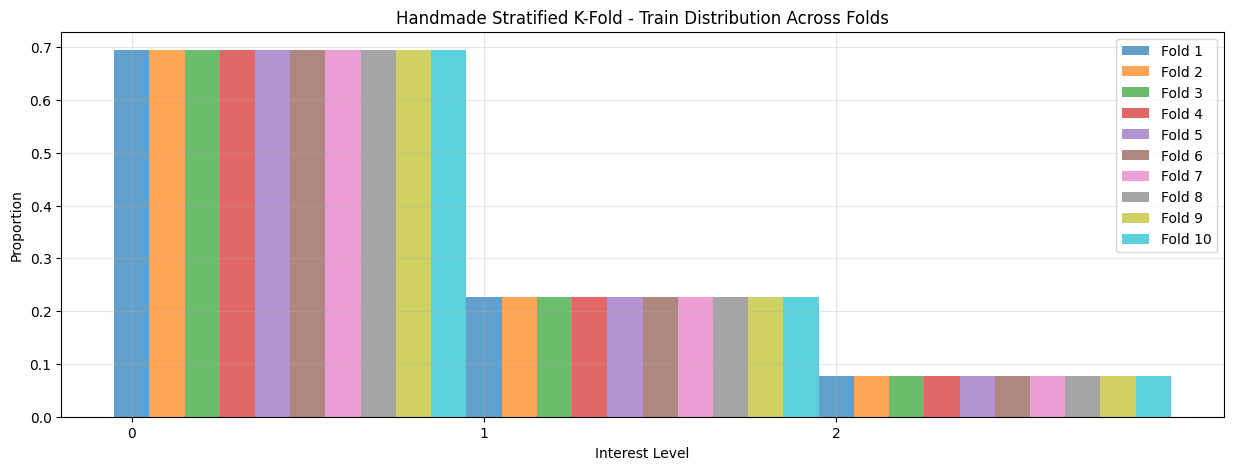

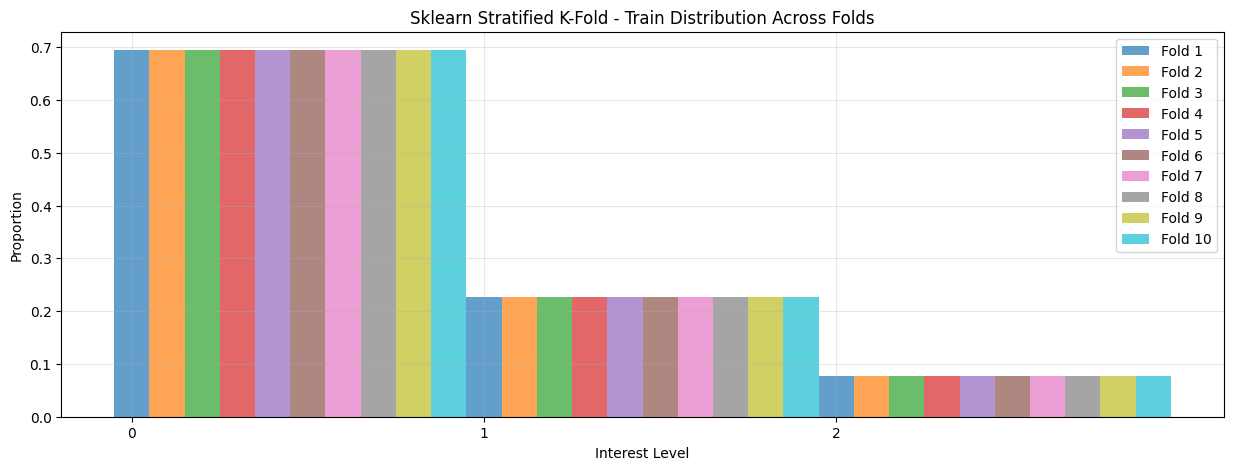

In [34]:
# Handmade Stratified K-Fold
plt.figure(figsize=(15, 5))
for i, (train_idx, test_idx) in enumerate(handmade['k-fold-stratified']):
    train_dist = df.loc[train_idx]['interest_level'].value_counts(normalize=True).sort_index()
    plt.bar(np.arange(len(train_dist)) + i*0.1, train_dist.values, width=0.1, alpha=0.7, label=f'Fold {i+1}')

plt.title('Handmade Stratified K-Fold - Train Distribution Across Folds')
plt.xlabel('Interest Level')
plt.ylabel('Proportion')
plt.xticks(np.arange(len(train_dist)), train_dist.index)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Sklearn Stratified K-Fold
plt.figure(figsize=(15, 5))
for i, (train_idx, test_idx) in enumerate(sklearn_splits['k-fold-stratified']):
    train_dist = df.iloc[train_idx]['interest_level'].value_counts(normalize=True).sort_index()
    plt.bar(np.arange(len(train_dist)) + i*0.1, train_dist.values, width=0.1, alpha=0.7, label=f'Fold {i+1}')

plt.title('Sklearn Stratified K-Fold - Train Distribution Across Folds')
plt.xlabel('Interest Level')
plt.ylabel('Proportion')
plt.xticks(np.arange(len(train_dist)), train_dist.index)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

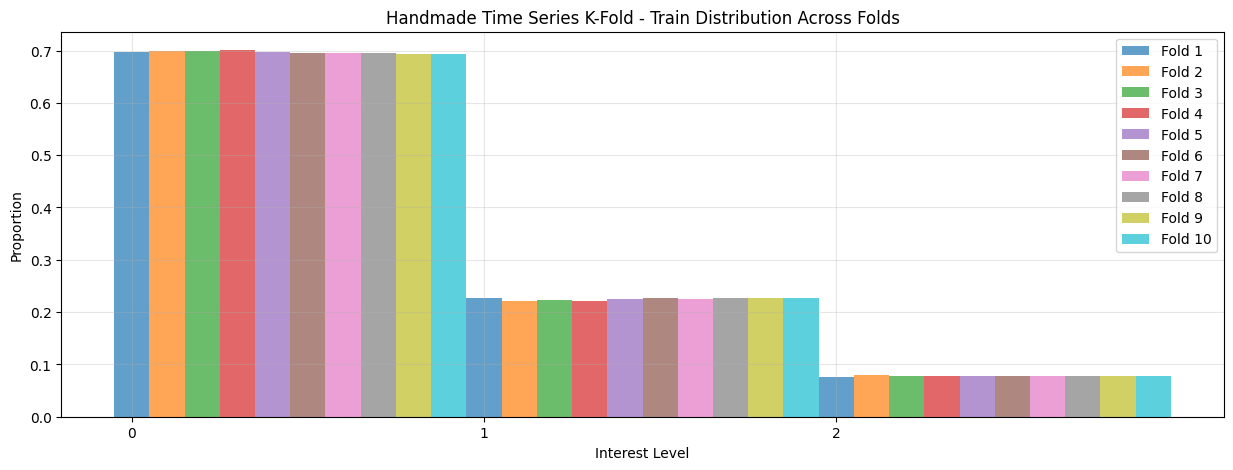

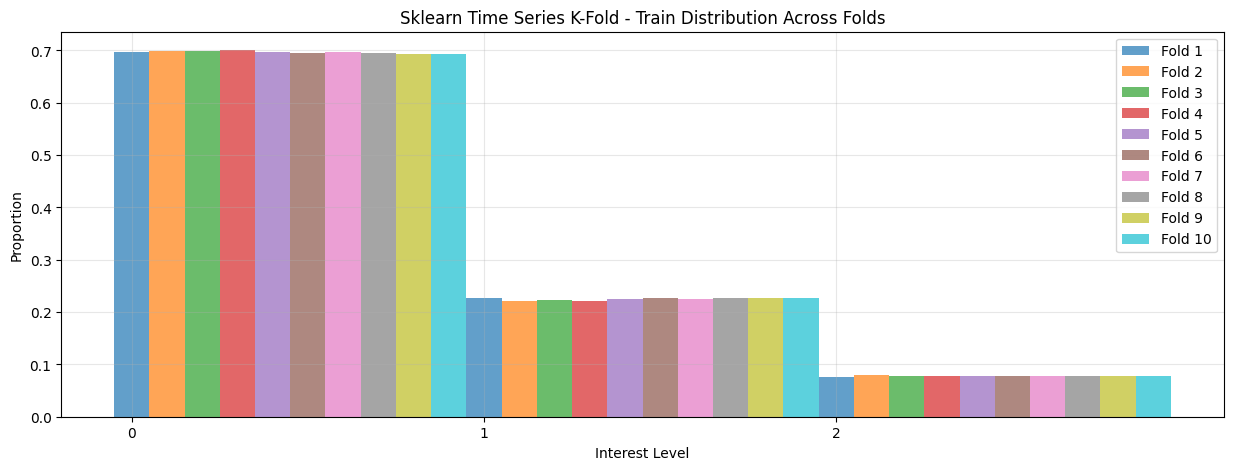

In [35]:
# Handmade Time Series K-Fold
plt.figure(figsize=(15, 5))
for i, (train_idx, test_idx) in enumerate(handmade['k-fold-timeseries']):
    train_dist = df.iloc[train_idx]['interest_level'].value_counts(normalize=True).sort_index()
    plt.bar(np.arange(len(train_dist)) + i*0.1, train_dist.values, width=0.1, alpha=0.7, label=f'Fold {i+1}')

plt.title('Handmade Time Series K-Fold - Train Distribution Across Folds')
plt.xlabel('Interest Level')
plt.ylabel('Proportion')
plt.xticks(np.arange(len(train_dist)), train_dist.index)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Sklearn Time Series K-Fold
plt.figure(figsize=(15, 5))
for i, (train_idx, test_idx) in enumerate(sklearn_splits['k-fold-timeseries']):
    train_dist = df.iloc[train_idx]['interest_level'].value_counts(normalize=True).sort_index()
    plt.bar(np.arange(len(train_dist)) + i*0.1, train_dist.values, width=0.1, alpha=0.7, label=f'Fold {i+1}')

plt.title('Sklearn Time Series K-Fold - Train Distribution Across Folds')
plt.xlabel('Interest Level')
plt.ylabel('Proportion')
plt.xticks(np.arange(len(train_dist)), train_dist.index)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

- Гистограммы незначительно отличаются друг от друга

#### Аналитическое сравнение методов кросс-валидации
Основные проблемы, которые решают модификации k-fold: Нарушение баланса данных, разделение групп по выборкам, разбинение временной шкалы (Модель может учиться на данных полученных позднее, а тестироваться на более ранных данных)
- Grouped k-fold - гарантирует, что данные из одной группы попадут только в одну выборку (train или test)
- Stratified k-fold - балансирует данные
- Time series k-fold - учит модель по старым данным, тестирует на новых

Очевидно, что для нашего набора данных наиболее полезная версия алгоритма Time-series k-fold

### 6. Отбор признаков

In [36]:
scores = pd.DataFrame({
    "modification": [],
    "MSE_train": [], "MAE_train": [], "R2_train": [],
    "MSE_val": [], "MAE_val": [], "R2_val": [], 
    "MSE_test": [], "MAE_test": [], "R2_test": [],
    "speed": [], "stability": []
})

#### Подсчет стабильности модели

In [37]:
def stability_score(model_template, X_full, y_full, k=5):
    folds = k_fold(k, X_full, y_full, shuffle=True, random_state=21)
    metric_scores = []
    
    scaler = StandardScaler()
    X_full_scaled = scaler.fit_transform(X_full)
    
    for train_idx, test_idx in folds:
        X_train_fold = X_full_scaled[train_idx]
        X_test_fold = X_full_scaled[test_idx]
        y_train_fold = y_full.iloc[train_idx]
        y_test_fold = y_full.iloc[test_idx]
        
        current_model = ElasticNet(
            alpha=0.01,
            max_iter=1000,
            tol=0.01,
            random_state=21
        )
        current_model.fit(X_train_fold, y_train_fold)
        
        y_pred = current_model.predict(X_test_fold)
        metric_scores.append(r2_score(y_test_fold, y_pred))
    
    variance = np.var(metric_scores, ddof=1)
    return variance

In [38]:
ss = StandardScaler()

alpha = 0.00001
max_iter=10000
tol = 0.00001

df_numeric = df.select_dtypes(include=[np.number])
df_train, df_val, df_test = Xy_split_val(df_numeric, 0.2, 0.2)

y_train, y_val, y_test = df_train.interest_level, df_val.interest_level, df_test.interest_level
X_train, X_val, X_test = df_train.drop('interest_level', axis=1), df_val.drop('interest_level', axis=1), df_test.drop('interest_level', axis=1)

In [39]:
X_train_norm = ss.fit_transform(X_train)
X_val_norm = ss.transform(X_val)
X_test_norm = ss.transform(X_test)

start_selection = time.time()

lasso = Lasso(alpha=alpha, random_state=21, max_iter=max_iter, tol=tol)
lasso.fit(X_train_norm, y_train)

time_selection_1 = time.time() - start_selection

##### Оценка стабильности классического Lasso

In [40]:
lasso_stability = Lasso(alpha=alpha, random_state=21, max_iter=max_iter, tol=tol)
stability1 = stability_score(lasso_stability, pd.concat([X_train, X_val]), pd.concat([y_train, y_val]))


In [41]:
features = X_train.columns
weights = dict(zip(features, lasso.coef_))
sorted_weights = sorted(weights.items(), key=lambda x: abs(x[1]), reverse=True)
top10_features = [feature for feature, weight in sorted_weights[:10]]

X_train_top10 = X_train[top10_features]
X_val_top10 = X_val[top10_features] 
X_test_top10 = X_test[top10_features]

X_train_top10_norm = ss.fit_transform(X_train_top10)
X_val_top10_norm = ss.transform(X_val_top10)
X_test_top10_norm = ss.transform(X_test_top10)

lasso_top10 = Lasso(alpha=alpha, random_state=21, max_iter=max_iter, tol=tol)
lasso_top10.fit(X_train_top10_norm, y_train)

time_selection_2 = time.time() - start_selection

lasso_top10_stability = Lasso(alpha=alpha, random_state=21, max_iter=max_iter, tol=tol)
stability2 = stability_score(lasso_top10_stability, pd.concat([X_train_top10, X_val_top10]), pd.concat([y_train, y_val]))

total_time_1 = time_selection_1
total_time_2  = time_selection_2

y_pred = lasso.predict(X_val_norm)
y_pred_top10 = lasso_top10.predict(X_val_top10_norm)
scores.loc[len(scores)] = [
    "Standart Lasso",
    mean_squared_error(y_train, lasso.predict(X_train_norm)),  # MSE_train
    mean_absolute_error(y_train, lasso.predict(X_train_norm)), # MAE_train  
    r2_score(y_train, lasso.predict(X_train_norm)),           # R2_train
    mean_squared_error(y_val, lasso.predict(X_val_norm)),     # MSE_val
    mean_absolute_error(y_val, lasso.predict(X_val_norm)),    # MAE_val
    r2_score(y_val, lasso.predict(X_val_norm)),              # R2_val
    mean_squared_error(y_test, lasso.predict(X_test_norm)),   # MSE_test
    mean_absolute_error(y_test, lasso.predict(X_test_norm)),  # MAE_test
    r2_score(y_test, lasso.predict(X_test_norm)),            # R2_test
    total_time_1,                                             # speed
    stability1                                                # stability
]
scores.loc[len(scores)] = [
    "Top10 features(weights) Lasso",
    mean_squared_error(y_train, lasso_top10.predict(X_train_top10_norm)),
    mean_absolute_error(y_train, lasso_top10.predict(X_train_top10_norm)),
    r2_score(y_train, lasso_top10.predict(X_train_top10_norm)),
    mean_squared_error(y_val, lasso_top10.predict(X_val_top10_norm)),
    mean_absolute_error(y_val, lasso_top10.predict(X_val_top10_norm)),
    r2_score(y_val, lasso_top10.predict(X_val_top10_norm)),
    mean_squared_error(y_test, lasso_top10.predict(X_test_top10_norm)),
    mean_absolute_error(y_test, lasso_top10.predict(X_test_top10_norm)),
    r2_score(y_test, lasso_top10.predict(X_test_top10_norm)),
    total_time_2,
    stability2
]
print(f"Без топ10:\n MSE:{mean_squared_error(y_val, y_pred)}\n MAE:{mean_absolute_error(y_val, y_pred)}\n R2: {r2_score(y_val, y_pred)}\n") 
print(f"Топ10:\n MSE:{mean_squared_error(y_val, y_pred_top10)}\n MAE:{mean_absolute_error(y_val, y_pred_top10)}\n R2: {r2_score(y_val, y_pred_top10)}\n")

Без топ10:
 MSE:0.37214829167087266
 MAE:0.4963270043811538
 R2: 0.07362797896049456

Топ10:
 MSE:0.3749070530345273
 MAE:0.4991080760350861
 R2: 0.06676071825498353



### Метод отбора признаков по пропускам

In [42]:
def null_cor(df, target_name, filter = 0.5, n = 10):
    target = df[target_name]
    features = df.drop(target_name, axis=1)

    nan_ratio = features.isnull().sum() / len(features)
    low_nan_features = nan_ratio[nan_ratio < filter].index
    
    cor = features[low_nan_features].corrwith(target).abs()
    
    top_features = cor.sort_values(ascending=False).head(n).index
    
    return top_features

In [43]:
start = time.time()

lasso_nullcor = Lasso(alpha=alpha, random_state=21, max_iter=max_iter, tol=tol)

df_new = pd.concat([df_numeric[null_cor(df_numeric, 'interest_level')], df_numeric['interest_level']], axis = 1)

df_new_train, df_new_val, df_new_test = Xy_split_val(df_new, 0.2, 0.2)

y_nullcor_train, y_nullcor_val, y_nullcor_test = df_new_train.interest_level, df_new_val.interest_level, df_new_test.interest_level
X_nullcor_train, X_nullcor_val, X_nullcor_test = df_new_train.drop('interest_level', axis=1), df_new_val.drop('interest_level', axis=1), df_new_test.drop('interest_level', axis=1)

lasso_nullcor.fit(X_nullcor_train, y_nullcor_train)
total_time_3 = time.time() - start

lasso_nullcor_stability = Lasso(alpha=alpha, random_state=21, max_iter=max_iter, tol=tol)
stability3 = stability_score(lasso_nullcor_stability, pd.concat([X_nullcor_train, X_nullcor_val]), pd.concat([y_nullcor_train, y_nullcor_val]))

y_nullcor_pred = lasso_nullcor.predict(X_nullcor_val)
scores.loc[len(scores)] = [
    "Top10 features(NaN) Lasso",
    mean_squared_error(y_nullcor_train, lasso_nullcor.predict(X_nullcor_train)),
    mean_absolute_error(y_nullcor_train, lasso_nullcor.predict(X_nullcor_train)),
    r2_score(y_nullcor_train, lasso_nullcor.predict(X_nullcor_train)),
    mean_squared_error(y_nullcor_val, lasso_nullcor.predict(X_nullcor_val)),
    mean_absolute_error(y_nullcor_val, lasso_nullcor.predict(X_nullcor_val)),
    r2_score(y_nullcor_val, lasso_nullcor.predict(X_nullcor_val)),
    mean_squared_error(y_nullcor_test, lasso_nullcor.predict(X_nullcor_test)),
    mean_absolute_error(y_nullcor_test, lasso_nullcor.predict(X_nullcor_test)),
    r2_score(y_nullcor_test, lasso_nullcor.predict(X_nullcor_test)),
    total_time_3,
    stability3
]
print(f"Метод отбора по пропускам:\n MSE:{mean_squared_error(y_nullcor_val, y_nullcor_pred)}\n MAE:{mean_absolute_error(y_nullcor_val, y_nullcor_pred)}\n R2: {r2_score(y_nullcor_val, y_nullcor_pred)}\n")


Метод отбора по пропускам:
 MSE:0.37399841320190275
 MAE:0.49914918910211764
 R2: 0.06902255456320938



### Метод важности перестановок

In [44]:
def perm_import(model, X, y, feature_names, repeats = 10):
    baseline_pred = model.predict(X)
    baseline_score = mean_absolute_error(y, baseline_pred)
    
    imp_scores = dict()
    
    for i, feature_name in enumerate(feature_names):
        feature_scores = []

        for _ in range(repeats):
            X_shuffle = X.copy()
            X_shuffle[:, i] = np.random.permutation(X_shuffle[:, i])
            
            y_shuffle = model.predict(X_shuffle)
            shuffle_score = mean_absolute_error(y, y_shuffle)
            
            feature_scores.append(shuffle_score - baseline_score)
        
        imp_scores[feature_name] = np.mean(feature_scores)

    return sorted(imp_scores.items(), key=lambda x: x[1], reverse=True)

In [45]:
start = time.time()

tmp_model = Lasso(alpha=alpha, random_state=21, max_iter=max_iter, tol=tol)

tmp_model.fit(X_train_norm, y_train)

feature_names = X_val.columns.tolist() 

prem_imp_features = perm_import(tmp_model, X_val_norm, y_val, feature_names)

features = [feature for feature, score in prem_imp_features[:10]]

X_train_pi = X_train[features]
X_val_pi = X_val[features]
X_test_pi = X_test[features]

ss_pi = StandardScaler()
X_train_pi_norm = ss_pi.fit_transform(X_train_pi)
X_val_pi_norm = ss_pi.transform(X_val_pi)
X_test_pi_norm = ss_pi.transform(X_test_pi)

perm_imp_model = Lasso(alpha=0.001, random_state=21)
perm_imp = perm_imp_model.fit(X_train_pi_norm, y_train)

total_time_4 = time.time() - start

lasso_pi_stability = Lasso(alpha=alpha, random_state=21, max_iter=max_iter)
stability4 = stability_score(lasso_pi_stability, pd.concat([X_train_pi, X_val_pi]), pd.concat([y_train, y_val]))

y_pred_pi = perm_imp.predict(X_val_pi_norm)


scores.loc[len(scores)] = [
    "Permutation Importance Lasso",
    mean_squared_error(y_train, perm_imp_model.predict(X_train_pi_norm)),
    mean_absolute_error(y_train, perm_imp_model.predict(X_train_pi_norm)),
    r2_score(y_train, perm_imp_model.predict(X_train_pi_norm)),
    mean_squared_error(y_val, perm_imp_model.predict(X_val_pi_norm)),
    mean_absolute_error(y_val, perm_imp_model.predict(X_val_pi_norm)),
    r2_score(y_val, perm_imp_model.predict(X_val_pi_norm)),
    mean_squared_error(y_test, perm_imp_model.predict(X_test_pi_norm)),
    mean_absolute_error(y_test, perm_imp_model.predict(X_test_pi_norm)),
    r2_score(y_test, perm_imp_model.predict(X_test_pi_norm)),
    total_time_4,
    stability4
]
print(f"Метод важности перестановок:\n MSE:{mean_squared_error(y_val, y_pred_pi)}\n MAE:{mean_absolute_error(y_val, y_pred_pi)}\n R2: {r2_score(y_val, y_pred_pi)}\n")

Метод важности перестановок:
 MSE:0.3744356246477396
 MAE:0.499168455999705
 R2: 0.06793422375593083



### Shap

In [46]:
start = time.time()

shap_model = Lasso(alpha=alpha, random_state=21, max_iter=max_iter)
shap_model.fit(X_train_norm, y_train)

explainer = shap.LinearExplainer(shap_model, X_train_norm, feature_names=feature_names)

shap_values = explainer(X_val_norm)

shap_importance = np.abs(shap_values.values).mean(axis=0)

shap_feature_importance = pd.DataFrame({
    'feature': feature_names,
    'shap_importance': shap_importance
}).sort_values('shap_importance', ascending=False)

top_10_shap_features = shap_feature_importance.head(10)['feature'].tolist()
print("Топ-10 признаков по SHAP:")
print(top_10_shap_features)

Топ-10 признаков по SHAP:
['NoFee', 'Doorman', 'HardwoodFloors', 'bathrooms', 'DogsAllowed', 'LaundryInBuilding', 'FitnessCenter', 'LaundryinBuilding', 'bedrooms', 'Pre-War']


In [47]:
X_train_shap = X_train[top_10_shap_features]
X_val_shap = X_val[top_10_shap_features]
X_test_shap = X_test[top_10_shap_features]

ss_shap = StandardScaler()
X_train_shap_norm = ss_shap.fit_transform(X_train_shap)
X_val_shap_norm = ss_shap.transform(X_val_shap)
X_test_shap_norm = ss_shap.transform(X_test_shap)


shap_selected_model = Lasso(alpha=alpha, random_state=21, max_iter=max_iter, tol=tol)
shap_selected_model.fit(X_train_shap_norm, y_train)

total_time_5 = time.time() - start
y_pred_shap = shap_selected_model.predict(X_val_shap_norm)

lasso_shap_stability = Lasso(alpha=alpha, random_state=21, max_iter=max_iter, tol=tol)
stability5 = stability_score(lasso_shap_stability, pd.concat([X_train_shap, X_val_shap]), pd.concat([y_train, y_val]))

scores.loc[len(scores)] = [
    "SHAP Lasso",
    mean_squared_error(y_train, shap_selected_model.predict(X_train_shap_norm)),
    mean_absolute_error(y_train, shap_selected_model.predict(X_train_shap_norm)),
    r2_score(y_train, shap_selected_model.predict(X_train_shap_norm)),
    mean_squared_error(y_val, shap_selected_model.predict(X_val_shap_norm)),
    mean_absolute_error(y_val, shap_selected_model.predict(X_val_shap_norm)),
    r2_score(y_val, shap_selected_model.predict(X_val_shap_norm)),
    mean_squared_error(y_test, shap_selected_model.predict(X_test_shap_norm)),
    mean_absolute_error(y_test, shap_selected_model.predict(X_test_shap_norm)),
    r2_score(y_test, shap_selected_model.predict(X_test_shap_norm)),
    total_time_5,
    stability5
]
print(f"SHAP:\n MSE:{mean_squared_error(y_val, y_pred_shap)}\n MAE:{mean_absolute_error(y_val, y_pred_shap)}\n R2: {r2_score(y_val, y_pred_shap)}\n")

SHAP:
 MSE:0.3730613222544896
 MAE:0.49761739937010274
 R2: 0.0713552129531092



In [48]:
scores

,modification,MSE_train,MAE_train,R2_train,MSE_val,MAE_val,R2_val,MSE_test,MAE_test,R2_test,speed,stability
0,Standart Lasso,0.360854,0.490870,0.070218,0.372148,0.496327,0.073628,0.364305,0.490900,0.074225,8.484305,0.000021
1,Top10 features(weights) Lasso,0.363054,0.493355,0.064552,0.374907,0.499108,0.066761,0.368453,0.494950,0.063682,12.704240,0.000024
2,Top10 features(NaN) Lasso,0.363099,0.493413,0.064436,0.373998,0.499149,0.069023,0.368006,0.495026,0.064820,0.609571,0.000020
3,Permutation Importance Lasso,0.363065,0.493774,0.064522,0.374436,0.499168,0.067934,0.367623,0.494708,0.065793,8.342736,0.000020
4,SHAP Lasso,0.362223,0.492217,0.066691,0.373061,0.497617,0.071355,0.366097,0.492582,0.069670,7.807694,0.000021


### 7.Оптимизация гиперпараметров

#### grid search

In [49]:
def grid_search(df, alphas, l1_ratios, target, test_size=0.2, random_state=21):
    train, test = Xy_split(df, test_size=test_size, random_state=random_state)
    X_train = train.drop(target, axis=1)
    y_train = train[target]
    X_test = test.drop(target, axis=1) 
    y_test = test[target]
    
    results = []
    best_score = -np.inf
    best_params = {}
    
    for alpha in alphas:
        for l1_ratio in l1_ratios:
            model = ElasticNet(
                alpha=alpha, 
                l1_ratio=l1_ratio, 
                random_state=21,
                max_iter=1000
            )
            model.fit(X_train, y_train)
            
            y_pred = model.predict(X_test)
            mae = mean_absolute_error(y_test, y_pred)
            
            results.append({
                'alpha': alpha,
                'l1_ratio': l1_ratio, 
                'mae_score': mae
            })
            
            if best_score == -np.inf or mae < best_score:
                best_score = mae
                best_params = {'alpha': alpha, 'l1_ratio': l1_ratio}
    
    return best_params, results

In [50]:
l1_ratios = np.linspace(0.0, 1.0, 5)
alphas = np.linspace(0.01, 10, 5)

grid_best_params, grid_results = grid_search(
    df=df_numeric,
    alphas=alphas, 
    l1_ratios=l1_ratios,
    target='interest_level'
)
print(grid_best_params)

c:\Users\Kirill\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.215e+03, tolerance: 1.546e+00 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent(
c:\Users\Kirill\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.675e+03, tolerance: 1.546e+00 Linear regression models with null weight for the l1 regularization term are more efficientl

{'alpha': np.float64(0.01), 'l1_ratio': np.float64(0.0)}


c:\Users\Kirill\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.707e+03, tolerance: 1.546e+00 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent(


### Random search

In [51]:
def random_search(df, param_distributions, target, n_iter=50, test_size=0.2, random_state=21):
    train, test = Xy_split(df, test_size=test_size, random_state=random_state)
    X_train = train.drop(target, axis=1)
    y_train = train[target]
    X_test = test.drop(target, axis=1)
    y_test = test[target]
    
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    results = []
    best_score = -np.inf
    best_params = {}

    rng = np.random.RandomState(random_state)

    for iteration in range(n_iter):
        current_params = {}
        
        for param_name, distribution in param_distributions.items():
            current_params[param_name] = rng.choice(distribution)
        
        try:
            model = ElasticNet(
                alpha=current_params['alpha'],
                l1_ratio=current_params['l1_ratio'],
                random_state=21,
                max_iter=1000,
                tol=0.01  
            )
            
            model.fit(X_train_scaled, y_train)
            
            y_pred = model.predict(X_test_scaled)
            score = r2_score(y_test, y_pred)
            
            result_entry = {
                'iteration': iteration,
                'alpha': current_params['alpha'],
                'l1_ratio': current_params['l1_ratio'],
                'score': score
            }
            results.append(result_entry)
            
            if score > best_score:
                best_score = score
                best_params = current_params.copy()
                
        except Exception as e:
            print(f"Ошибка при параметрах {current_params}: {e}")
            continue
    
    return best_params, results


In [52]:
param_distributions = {'alpha': alphas, 'l1_ratio': l1_ratios}

random_best_params, random_results = random_search(
    df=df_numeric,
    param_distributions=param_distributions,
    target='interest_level',
    n_iter=10,
    random_state=21
)

print(random_best_params)

c:\Users\Kirill\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.567e+03, tolerance: 1.546e+02 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent(
c:\Users\Kirill\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.675e+03, tolerance: 1.546e+02 Linear regression models with null weight for the l1 regularization term are more efficientl

{'alpha': np.float64(0.01), 'l1_ratio': np.float64(0.0)}


c:\Users\Kirill\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 7.632e+03, tolerance: 1.546e+02 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent(


In [53]:
def evaluate_final_model(params, method_name):
    start_time = time.time()
    
    train, val, test = Xy_split_val(df_numeric, test_size=0.2, validation_size=0.2, random_state=21)
    
    X_train = train.drop('interest_level', axis=1)
    y_train = train['interest_level']
    X_val = val.drop('interest_level', axis=1)
    y_val = val['interest_level']
    X_test = test.drop('interest_level', axis=1)
    y_test = test['interest_level']
    
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)
    X_test_scaled = scaler.transform(X_test)
    
    model = ElasticNet(
        alpha=params['alpha'],
        l1_ratio=params['l1_ratio'],
        random_state=21,
        max_iter=1000
    )
    
    model.fit(X_train_scaled, y_train)
    
    y_pred_train = model.predict(X_train_scaled)
    y_pred_val = model.predict(X_val_scaled)
    y_pred_test = model.predict(X_test_scaled)
    
    mse_train = mean_squared_error(y_train, y_pred_train)
    mae_train = mean_absolute_error(y_train, y_pred_train)
    r2_train = r2_score(y_train, y_pred_train)
    
    mse_val = mean_squared_error(y_val, y_pred_val)
    mae_val = mean_absolute_error(y_val, y_pred_val)
    r2_val = r2_score(y_val, y_pred_val)
    
    mse_test = mean_squared_error(y_test, y_pred_test)
    mae_test = mean_absolute_error(y_test, y_pred_test)
    r2_test = r2_score(y_test, y_pred_test)
    
    execution_time = time.time() - start_time
    
    return {
        'method': method_name,
        'params': params,
        'mse_train': mse_train,
        'mae_train': mae_train,
        'r2_train': r2_train,
        'mse_val': mse_val,
        'mae_val': mae_val,
        'r2_val': r2_val,
        'mse_test': mse_test,
        'mae_test': mae_test,
        'r2_test': r2_test,
        'time': execution_time,
        'model': model
    }

In [54]:
final_results = []

grid_final = evaluate_final_model(grid_best_params, 'Grid Search Final')
final_results.append(grid_final)

random_final = evaluate_final_model(random_best_params, 'Random Search Final')
final_results.append(random_final)

final_comparison = pd.DataFrame([{
    'Method': r['method'],
    'Alpha': r['params']['alpha'],
    'L1_Ratio': r['params']['l1_ratio'],
    'MSE_train': r['mse_train'],
    'MAE_train': r['mae_train'], 
    'R2_train': r['r2_train'],
    'MSE_val': r['mse_val'],
    'MAE_val': r['mae_val'],
    'R2_val': r['r2_val'],
    'MSE_test': r['mse_test'],
    'MAE_test': r['mae_test'],
    'R2_test': r['r2_test'],
    'Time_sec': r['time']
} for r in final_results])

print("\nФИНАЛЬНОЕ СРАВНЕНИЕ МОДЕЛЕЙ:")
print(final_comparison.round(4))

best_model_idx = final_comparison['R2_val'].idxmax()
best_model_info = final_results[best_model_idx]

print(f"\n=== ЛУЧШАЯ МОДЕЛЬ ===")
print(f"Метод: {best_model_info['method']}")
print(f"Параметры: {best_model_info['params']}")
print(f"R2 на валидации: {best_model_info['r2_val']:.4f}")
print(f"R2 на тесте: {best_model_info['r2_test']:.4f}")
print(f"MAE на тесте: {best_model_info['mae_test']:.4f}")
print(f"MSE на тесте: {best_model_info['mse_test']:.4f}")

best_final_model = best_model_info['model']

scores.loc[len(scores)] = [
    f"Best {best_model_info['method']}",
    best_model_info['mse_train'],
    best_model_info['mae_train'], 
    best_model_info['r2_train'],
    best_model_info['mse_val'],
    best_model_info['mae_val'],
    best_model_info['r2_val'],
    best_model_info['mse_test'],
    best_model_info['mae_test'], 
    best_model_info['r2_test'],
    best_model_info['time'],
    stability_score(best_final_model, pd.concat([X_train, X_val]), pd.concat([y_train, y_val]))
]

print("\nОбновленная таблица scores с лучшей моделью:")
print(scores.round(4))

c:\Users\Kirill\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.348e+03, tolerance: 1.149e+00 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent(
c:\Users\Kirill\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.348e+03, tolerance: 1.149e+00 Linear regression models with null weight for the l1 regularization term are more efficientl


ФИНАЛЬНОЕ СРАВНЕНИЕ МОДЕЛЕЙ:
                Method  Alpha  L1_Ratio  MSE_train  MAE_train  R2_train  \
0    Grid Search Final   0.01       0.0     0.3609     0.4912    0.0702   
1  Random Search Final   0.01       0.0     0.3609     0.4912    0.0702   

   MSE_val  MAE_val  R2_val  MSE_test  MAE_test  R2_test  Time_sec  
0   0.3717   0.4966  0.0747    0.3643    0.4913   0.0741   17.4692  
1   0.3717   0.4966  0.0747    0.3643    0.4913   0.0741   18.3167  

=== ЛУЧШАЯ МОДЕЛЬ ===
Метод: Grid Search Final
Параметры: {'alpha': np.float64(0.01), 'l1_ratio': np.float64(0.0)}
R2 на валидации: 0.0747
R2 на тесте: 0.0741
MAE на тесте: 0.4913
MSE на тесте: 0.3643

Обновленная таблица scores с лучшей моделью:
                    modification  MSE_train  MAE_train  R2_train  MSE_val  \
0                 Standart Lasso     0.3609     0.4909    0.0702   0.3721   
1  Top10 features(weights) Lasso     0.3631     0.4934    0.0646   0.3749   
2      Top10 features(NaN) Lasso     0.3631     0.4934    

#### Optuna для ElasticNet

In [55]:
### 7.4 Optuna для ElasticNet

def objective_optuna(trial):
    alpha = trial.suggest_float('alpha', 0.001, 1.0, log=True)
    l1_ratio = trial.suggest_float('l1_ratio', 0.0, 1.0)
    
    train, val, test = Xy_split_val(df_numeric, test_size=0.2, validation_size=0.2, random_state=21)
    
    X_train = train.drop('interest_level', axis=1)
    y_train = train['interest_level']
    X_val = val.drop('interest_level', axis=1)
    y_val = val['interest_level']
    
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)
    
    model = ElasticNet(
        alpha=alpha, 
        l1_ratio=l1_ratio, 
        random_state=21,
        max_iter=1000
    )
    
    model.fit(X_train_scaled, y_train)
    
    y_pred = model.predict(X_val_scaled)
    score = r2_score(y_val, y_pred)
    
    return score

In [56]:
study = optuna.create_study(direction='maximize')
study.optimize(objective_optuna, n_trials=20)

print("Лучшие гиперпараметры:")
print(study.best_params)
print(f"Лучший R2: {study.best_value:.4f}")

optuna_best_params = study.best_params

[I 2025-10-23 12:25:59,814] A new study created in memory with name: no-name-6203eca4-36a7-4c47-8874-610779ea5c4f
[I 2025-10-23 12:25:59,933] Trial 0 finished with value: -4.626814238406496e-07 and parameters: {'alpha': 0.2899019724036888, 'l1_ratio': 0.9159557692849197}. Best is trial 0 with value: -4.626814238406496e-07.
[I 2025-10-23 12:26:00,050] Trial 1 finished with value: -4.626814238406496e-07 and parameters: {'alpha': 0.6823703970475422, 'l1_ratio': 0.2441125394608462}. Best is trial 0 with value: -4.626814238406496e-07.
[I 2025-10-23 12:26:02,819] Trial 2 finished with value: 0.07491317674630149 and parameters: {'alpha': 0.006713709385407773, 'l1_ratio': 0.025551938721177447}. Best is trial 2 with value: 0.07491317674630149.
[I 2025-10-23 12:26:02,971] Trial 3 finished with value: 0.005594140525592484 and parameters: {'alpha': 0.14390315795208075, 'l1_ratio': 0.48428125573436864}. Best is trial 2 with value: 0.07491317674630149.
[I 2025-10-23 12:26:03,398] Trial 4 finished wi

Лучшие гиперпараметры:
{'alpha': 0.0011664383818969903, 'l1_ratio': 0.4591698945853149}
Лучший R2: 0.0753


In [57]:
### 7.5 Сравнение подходов

def evaluate_model(params, method_name):
    start_time = time.time()
    
    train, val, test = Xy_split_val(df_numeric, test_size=0.2, validation_size=0.2, random_state=21)
    
    X_train = train.drop('interest_level', axis=1)
    y_train = train['interest_level']
    X_val = val.drop('interest_level', axis=1)
    y_val = val['interest_level']
    X_test = test.drop('interest_level', axis=1)
    y_test = test['interest_level']
    
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)
    X_test_scaled = scaler.transform(X_test)
    
    model = ElasticNet(
        alpha=params['alpha'],
        l1_ratio=params['l1_ratio'],
        random_state=21,
        max_iter=1000
    )
    
    model.fit(X_train_scaled, y_train)
    
    y_pred_test = model.predict(X_test_scaled)
    test_r2 = r2_score(y_test, y_pred_test)
    
    execution_time = time.time() - start_time
    
    return {
        'method': method_name,
        'test_r2': test_r2,
        'time': execution_time
    }


In [58]:
comparison_results = []

grid_best_params = {'alpha': 0.001, 'l1_ratio': 0.0}
comparison_results.append(evaluate_model(grid_best_params, 'Grid Search'))

random_best_params = random_best_params
comparison_results.append(evaluate_model(random_best_params, 'Random Search'))

comparison_results.append(evaluate_model(optuna_best_params, 'Optuna'))

comparison_df = pd.DataFrame(comparison_results)
print("\nСравнение методов оптимизации")
print(comparison_df[['method', 'test_r2', 'time']])

c:\Users\Kirill\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.343e+03, tolerance: 1.149e+00 Linear regression models with null weight for the l1 regularization term are more efficiently fitted using one of the solvers implemented in sklearn.linear_model.Ridge/RidgeCV instead.
  model = cd_fast.enet_coordinate_descent(
c:\Users\Kirill\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.348e+03, tolerance: 1.149e+00 Linear regression models with null weight for the l1 regularization term are more efficientl


Сравнение методов оптимизации
          method   test_r2       time
0    Grid Search  0.074226  18.046467
1  Random Search  0.074150  17.413066
2         Optuna  0.074111   0.420620


In [59]:
### 7.6 Optuna с кросс-валидацией

def objective_optuna_cv(trial):
    alpha = trial.suggest_float('alpha', 0.001, 1.0, log=True)
    l1_ratio = trial.suggest_float('l1_ratio', 0.0, 1.0)
    
    k = 5
    folds = k_fold(k, df_numeric.drop('interest_level', axis=1), df_numeric['interest_level'])
    
    scores = []
    
    for train_idx, test_idx in folds:
        X_train_fold = df_numeric.iloc[train_idx].drop('interest_level', axis=1)
        X_test_fold = df_numeric.iloc[test_idx].drop('interest_level', axis=1)
        y_train_fold = df_numeric.iloc[train_idx]['interest_level']
        y_test_fold = df_numeric.iloc[test_idx]['interest_level']
        
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train_fold)
        X_test_scaled = scaler.transform(X_test_fold)
        
        model = ElasticNet(
            alpha=alpha, 
            l1_ratio=l1_ratio, 
            random_state=21,
            max_iter=1000
        )
        
        model.fit(X_train_scaled, y_train_fold)
        y_pred = model.predict(X_test_scaled)
        score = r2_score(y_test_fold, y_pred)
        scores.append(score)
    
    return np.mean(scores)

In [61]:
study_cv = optuna.create_study(direction='maximize')
study_cv.optimize(objective_optuna_cv, n_trials=15)

print("\n=== Optuna with Cross-Validation ===")
print("Лучшие гиперпараметры:")
print(study_cv.best_params)
print(f"Лучший R2: {study_cv.best_value:.4f}")

# Сравнение с обычной Optuna
cv_best_params = study_cv.best_params
comparison_results.append(evaluate_model(cv_best_params, 'Optuna CV'))

# Финальное сравнение
final_comparison_df = pd.DataFrame(comparison_results)
print("\n=== Финальное сравнение всех методов ===")
print(final_comparison_df[['method', 'test_r2', 'time']])

# Анализ результатов
best_method = final_comparison_df.loc[final_comparison_df['test_r2'].idxmax()]
print(f"\nЛучший метод: {best_method['method']}")
print(f"Лучший test R2: {best_method['test_r2']:.4f}")

[I 2025-10-23 12:44:32,370] A new study created in memory with name: no-name-2f5a05e1-2cf2-4fe2-94c5-b9ab372e686f
[I 2025-10-23 12:44:33,201] Trial 0 finished with value: 0.06558504257903333 and parameters: {'alpha': 0.036290546181525045, 'l1_ratio': 0.2638808167720197}. Best is trial 0 with value: 0.06558504257903333.
[I 2025-10-23 12:44:33,694] Trial 1 finished with value: 0.030902019701802973 and parameters: {'alpha': 0.06670289110246559, 'l1_ratio': 0.6639463350681076}. Best is trial 0 with value: 0.06558504257903333.
[I 2025-10-23 12:44:35,570] Trial 2 finished with value: 0.06820906631776909 and parameters: {'alpha': 0.0025579739591750496, 'l1_ratio': 0.27939354975307806}. Best is trial 2 with value: 0.06820906631776909.
[I 2025-10-23 12:44:36,065] Trial 3 finished with value: 0.03606994922595812 and parameters: {'alpha': 0.06725658045824094, 'l1_ratio': 0.5955105905209831}. Best is trial 2 with value: 0.06820906631776909.
[I 2025-10-23 12:44:38,540] Trial 4 finished with value: 


=== Optuna with Cross-Validation ===
Лучшие гиперпараметры:
{'alpha': 0.004496952785041974, 'l1_ratio': 0.9539170592502709}
Лучший R2: 0.0685

=== Финальное сравнение всех методов ===
          method   test_r2       time
0    Grid Search  0.074226  18.046467
1  Random Search  0.074150  17.413066
2         Optuna  0.074111   0.420620
3      Optuna CV  0.072756   0.304648
4      Optuna CV  0.072206   0.189782

Лучший метод: Grid Search
Лучший test R2: 0.0742
